**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These tutorials use a CPU and the full original SIRDS bank. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `7a0813987944`](https://github.com/OJWatson/metis/tree/7a081398794492c82d92812b5801900f62f8639a).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Short uv setup cell shared by downloadable notebooks."""

import os
from pathlib import Path
import re
import shlex
import subprocess
import sys


def prepare_colab(revision):
    """Use the checkout's locked environment in Colab's active interpreter."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    if not (os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION")):
        print("Using your local METIS environment.")
        return
    # The source commit matches the results saved in this notebook.
    source = Path("/content/metis-tutorial")
    commands = f'''
set -euo pipefail
export PATH="$HOME/.local/bin:$PATH"
command -v uv >/dev/null || curl -LsSf https://astral.sh/uv/0.7.22/install.sh | sh
[ -d {source}/.git ] || git clone -q https://github.com/OJWatson/metis.git {source}
git -C {source} fetch -q origin {revision}
git -C {source} checkout -q --detach {revision}
uv sync --project {source} --python {shlex.quote(sys.executable)} --locked --inexact --no-dev --extra docs --no-editable
'''
    subprocess.run(
        ["bash", "-c", commands], check=True,
        env={**os.environ, "UV_PROJECT_ENVIRONMENT": sys.prefix, "UV_NO_MODIFY_PATH": "1"},
    )
    print("METIS is ready. If Colab reports a library-version conflict or asks for a restart, restart the session, then Run all.")


prepare_colab("7a081398794492c82d92812b5801900f62f8639a")


The autoregressive transformer model is a flexible and deterministic surrogate.

## When this might be a good fit

The transformer is a great option when a deterministic surrogate suffices. Furthermore, it is more flexible than an MLP, supporting conditioning on both static inputs and sequences. The package predicts the time grid used for training. Observed sequence channels can be supplied through `observed_outputs`; their history before each prediction time is used as conditioning.

Unfortunately, Transformer surrogates are slower to train and infer with and often require more tuning to match the performance of an MLP. Compare complete predicted trajectories on the validation bank, since next-step training loss can conceal errors that accumulate during generation.

## How transformers work

### Architectural walkthrough
The transformer architecture is substantially more complex than an MLP's so we won't cover it in great depth here.

The most important part of the Transformer architecture is the *self-attention* mechanism which enables the model to process sequence data in a highly expressive way. In an attention computation, the entries of an incoming sequence $x_1, x_2, \dots, x_n$ are given corresponding *query*, *key* and *value* vectors via projection matrices (e.g. $q_1=W_{q}x_1^T$).  These entries are collected in a $Q$ (query), $K$ (key) and $V$ (value) matrix and the transformed sequence is computed via $y=\mathrm{softmax}(\frac{QK^T}{\sqrt{d}})V$. In an autoregressive transformer this computation is restricted so that query vectors may only *attend* to key vectors from the past:

![Causal self-attention mask showing that x4 can attend to x1 through x4 but not x5.](https://ojwatson.github.io/metis/models/images/causal-attention-mask.svg)

Causal self-attention: each input may attend to itself and earlier inputs, but not future inputs.

In practice *multi-head* attention is used, where models have several projection matrices and perform attention over the different sets of projections independently and in parallel and then combine the results.

![Multi-head attention with query, key, and value sequences for four heads.](https://ojwatson.github.io/metis/models/images/multi-head-attention-sequences.svg)

Multi-head attention: Each block is a projected sequence of query, key, or value vectors.


During training the attention computation can be done over entire sequences at once (this is a major strength of the transformer), however, during inference, the sequence is iteratively generated. Since the latest entry in the sequence still needs to attend to every entry that came before it we are forced to either repeatedly recompute prior *key* and *value* vectors or to store them in a *Key-Value Cache* (KV-Cache). The low-level architecture includes a KV-cache; the package prediction interface currently recomputes the history.

In METIS we also support options like interleaving full self-attention with *sliding window* attention which halves the maximum size of the attention window for a computational speedup:

![Sliding window attention limits each position to nearby earlier positions.](https://ojwatson.github.io/metis/models/images/sliding-window-attention-mask.svg)

Sliding window self-attention: Later tokens may not attend to the furthest tokens in the past.

We additionally support specifying fewer key-value heads (i.e. projections) than query heads to make attention more efficient and reduce the size of the KV-cache. This is known as *Grouped-Query Attention*.

![Grouped-query attention with four query heads sharing two key-value heads.](https://ojwatson.github.io/metis/models/images/grouped-query-attention-sequences.svg)

Grouped-query attention: Multiple query heads share each key-value head.

### Training

Language transformers train with *Cross-Entropy Loss* over tokens but since our data is typically continuous, we use a next-token MSE loss.

## Configuring a Transformer

Pass architecture options to `Surrogate("transformer", model_options={...})`:

| Option | Meaning | Default |
|---|---|---:|
| `n_layer` | Number of transformer blocks | 2 |
| `n_embd` | Hidden dimension (width) | 64 |
| `n_head` | Number of query heads | 4 |
| `n_kv_head` | Number of key/value heads | 4 |
| `window_pattern` | Full (`L`) or shorter (`S`) attention; `SL` alternates | `L` |

The width must divide evenly among query heads, with an even dimension per head;
key/value heads must divide query heads. Dimensions and the time grid are
inferred from the simulation bank. Optional `rope_base` and
`in_and_out_biases` control rotary embeddings and projection biases.

The same options are available through [Hydra](https://ojwatson.github.io/metis/basics/hydra.html):

```bash
uv run metis train model=transformer model.model_options.n_layer=4 model.model_options.n_embd=128
```

## Training on SIRDS

We use the full [SIRDS bank](https://ojwatson.github.io/metis/basics/sirds-example.html): 1,000 parameter
settings, five realisations per setting and all 200 daily outputs. The grouped
split matches the [training tutorial](https://ojwatson.github.io/metis/basics/training.html): 600 settings for
training, 200 for validation and 200 for testing. This CPU fit uses 1,000
optimizer steps.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from metis import load_example, Surrogate, TrainingConfig

bank = load_example()
split = bank.split(seed=42)

In [2]:
model = Surrogate(
    "transformer",
    model_options={"n_layer": 2, "n_head": 4, "n_kv_head": 4, "n_embd": 64},
).fit(
    split.train, split.validation,
    config=TrainingConfig(steps=1000, batch_size=64, eval_every=100, seed=42),
)

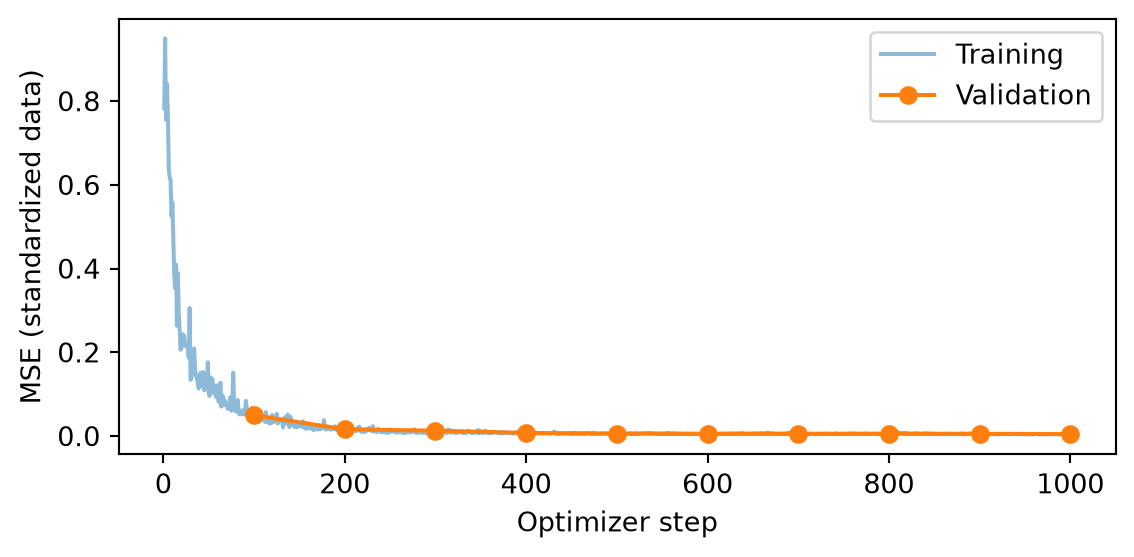

In [3]:
#| code-fold: true
#| code-summary: "Plot training and validation loss"
#| fig-cap: "Transformer: loss on the full SIRDS bank: 600 training settings and 200 validation settings."
validation = [row for row in model.history if "validation_loss" in row]
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot([row["step"] for row in model.history],
        [row["train_loss"] for row in model.history], alpha=0.5, label="Training")
ax.plot([row["step"] for row in validation],
        [row["validation_loss"] for row in validation], "o-", label="Validation")
ax.set(xlabel="Optimizer step", ylabel="MSE (standardized data)")
ax.legend()
fig.tight_layout()
plt.show()

*Transformer: loss on the full SIRDS bank: 600 training settings and 200 validation settings.*

Predict an entire trajectory at the first held-out parameter setting. A
deterministic prediction aims to capture the conditional average, whereas the
simulator produces different realisations at the same inputs.

In [4]:
inputs = split.test.inputs[:1]
prediction = model.predict(inputs)[0]
print("Predicted times × outputs:", prediction.shape)

Predicted times × outputs: (200, 4)


/home/runner/work/metis/metis/src/metis/surrogate.py:672: UserWarning: Inputs outside the training ranges for ['I_0']; predictions extrapolate and are not clipped.
  array = self._inputs(inputs)


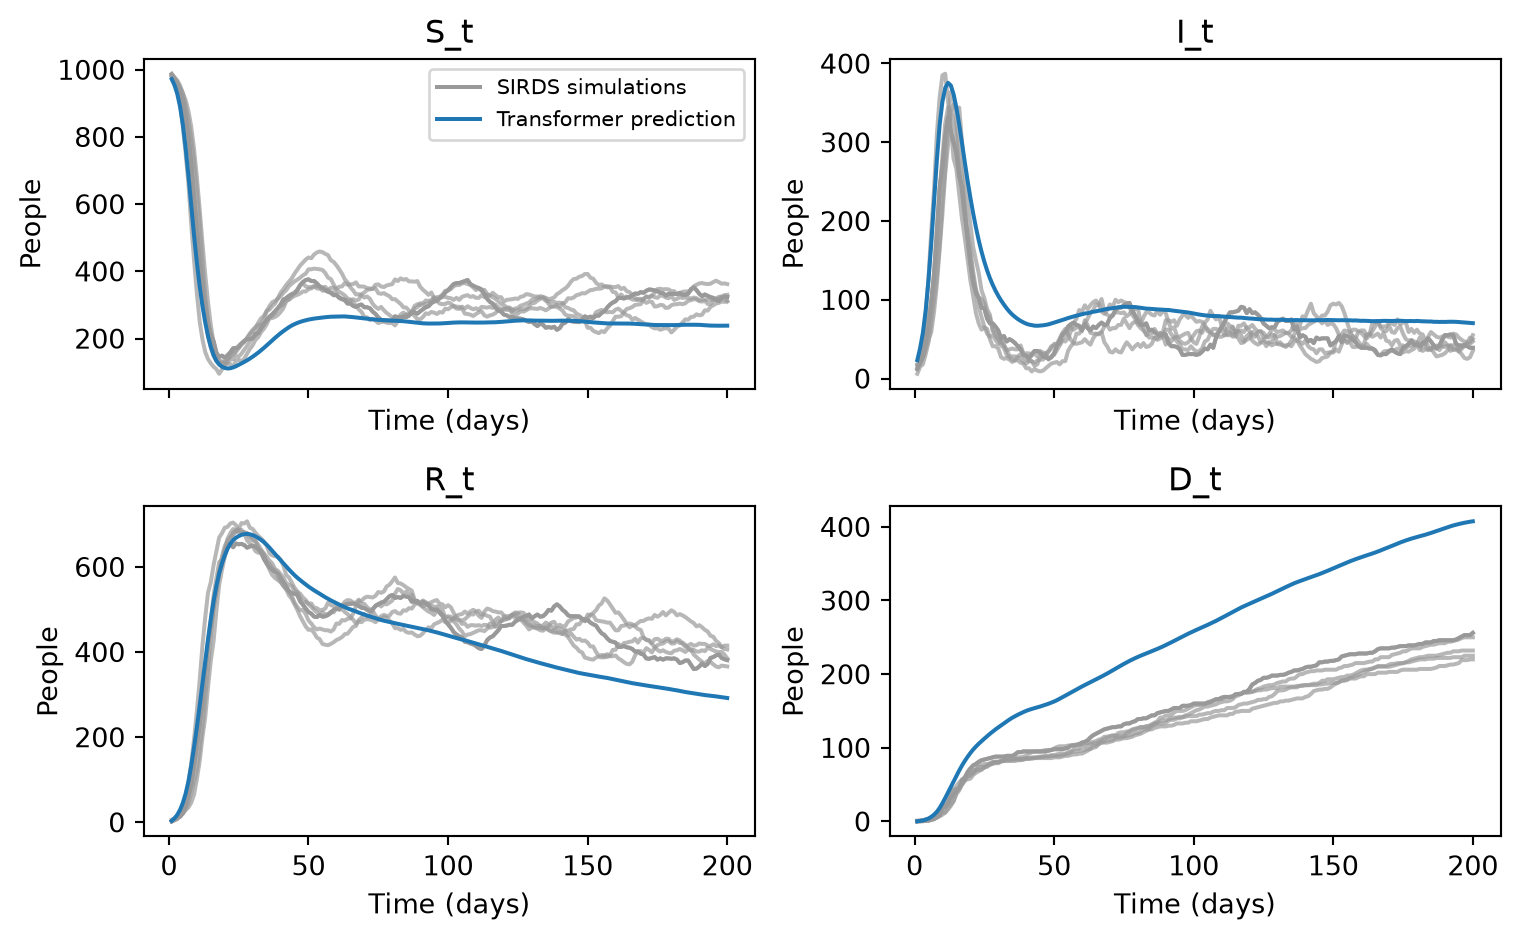

In [5]:
#| code-fold: true
#| code-summary: "Compare the prediction with SIRDS simulations"
#| fig-cap: "Transformer: prediction and five SIRDS simulations at the first held-out parameter setting. The model was fitted to 600 settings from the full 200-day SIRDS bank."
same_inputs = np.all(split.test.inputs == inputs[0], axis=1)
replicates = split.test.outputs[same_inputs]
fig, axes = plt.subplots(2, 2, figsize=(8, 5), sharex=True)
for channel, ax in enumerate(axes.flat):
    ax.plot(bank.times, replicates[:, :, channel].T, color="0.6", alpha=0.7)
    ax.plot(bank.times, replicates[0, :, channel], color="0.6", label="SIRDS simulations")
    ax.plot(bank.times, prediction[:, channel], color="C0", label="Transformer prediction")
    ax.set(title=bank.output_names[channel], xlabel="Time (days)", ylabel="People")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()

*Transformer: prediction and five SIRDS simulations at the first held-out parameter setting. The model was fitted to 600 settings from the full 200-day SIRDS bank.*

A falling next-step loss does not ensure accurate generation over all 200 days.
Compare complete predictions over the whole held-out bank, as in the
[training tutorial](https://ojwatson.github.io/metis/basics/training.html).

## Conditioning on an observed sequence

Suppose the infected trajectory is already observed and you want to predict
the other SIRDS compartments. METIS can treat `I_t` as an input sequence and
learn to predict `S_t`, `R_t` and `D_t`. To try this, fit a separate model using
the `bank` and `split` created above:

In [6]:
conditioned_model = Surrogate(
    "transformer", observed_outputs=["I_t"],
).fit(
    split.train, split.validation,
    config=TrainingConfig(steps=1000, eval_every=100, seed=42),
)

same_group = np.all(split.test.inputs == split.test.inputs[0], axis=1)
new_inputs = split.test.inputs[same_group]
held_out = split.test.outputs[same_group]
infected_paths = held_out[:, :, bank.output_names.index("I_t")]
conditioned_prediction = conditioned_model.predict(
    new_inputs, conditioning={"I_t": infected_paths},
)
prediction_by_channel = {
    name: conditioned_prediction[:, :, channel]
    for channel, name in enumerate(conditioned_model.output_names)
}
print({name: values.shape for name, values in prediction_by_channel.items()})

{'S_t': (5, 200), 'R_t': (5, 200), 'D_t': (5, 200)}


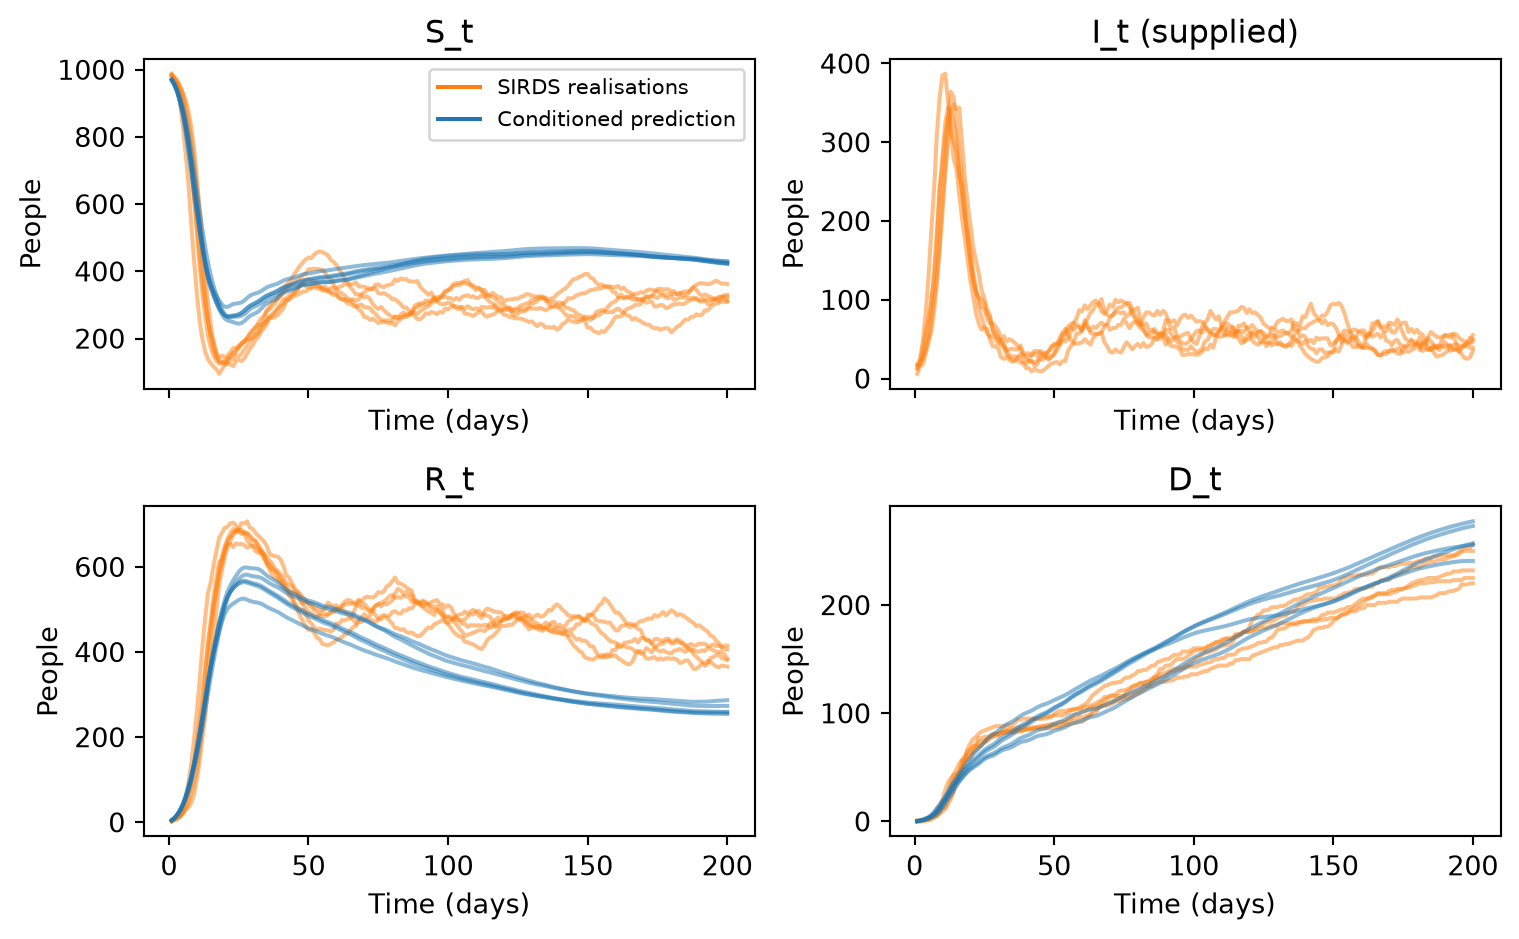

In [7]:
#| code-fold: true
#| code-summary: "Compare conditioned predictions with the five held-out SIRDS realisations"
#| fig-cap: "Conditioned transformer fitted on 600 SIRDS settings. The infected paths from five realisations at the first held-out setting are supplied as observations; blue trajectories predict S, R and D using the infected history available before each time."
fig, axes = plt.subplots(2, 2, figsize=(8, 5), sharex=True)
for channel, ax in enumerate(axes.flat):
    name = bank.output_names[channel]
    ax.plot(bank.times, held_out[:, :, channel].T, color="C1", alpha=0.5)
    ax.plot([], [], color="C1", label="SIRDS realisations")
    if name in prediction_by_channel:
        ax.plot(bank.times, prediction_by_channel[name].T, color="C0", alpha=0.5)
        ax.plot([], [], color="C0", label="Conditioned prediction")
    ax.set(title=f"{name} (supplied)" if name == "I_t" else name,
           xlabel="Time (days)", ylabel="People")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()

*Conditioned transformer fitted on 600 SIRDS settings. The infected paths from five realisations at the first held-out setting are supplied as observations; blue trajectories predict S, R and D using the infected history available before each time.*

Here `infected_paths` has shape `(number_of_runs, number_of_times)` on the
training time grid. The transformer only uses infected observations from
before each prediction time. Choose an observed channel only if it will be
available when using the surrogate; otherwise this changes the problem you
are trying to solve.